# Framework Validation

## Constraint validation across all matching profiles and three NTS components

### 1. Import Libraries

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

### 2. Set Up File Paths

In [2]:
# AI Collaboration Record
# Tool: ChatGPT
# Purpose: Load the inputs required to validate all unique unconstrained
# NTS0611 Age-Gender lookup combinations.
# Prompt:
# See AI_PROMPTS.md

TOLERANCE = 1e-8

project_root = Path.cwd().parents[1]
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

profile_space_path = (
    project_root
    / "output"
    / "demographic_profiles"
    / "constrained_representative_profile_space.parquet"
)
nts0611_path = (
    project_root
    / "data"
    / "nts"
    / "harmonised"
    / "nts0611a_trip_purpose_probability.json"
)
behavioural_evidence_path = (
    project_root
    / "output"
    / "behavioural_evidence"
    / "nts_behavioural_evidence_layer.json"
)
plot_output_directory = (
    project_root
    / "output"
    / "validation"
    / "nts0611_unconstrained_plots"
)

representative_profile_space = pd.read_parquet(profile_space_path)
nts0611_df = pd.read_json(nts0611_path)

with open(behavioural_evidence_path, "r", encoding="utf-8") as file:
    assembled_behavioural_evidence = json.load(file)

from src.demographic_behaviour_layers_integration import (
    DEMOGRAPHIC_ATTRIBUTES,
    construct_constrained_behaviour_representation,
)

### 3. Define five validation conditions and select every matching profile

Each visualisation defines one constraint combination. Every profile in the constrained representative profile space that matches all listed conditions is retained and validated. No single profile represents the matching set during numerical validation. One already-validated profile is used for each figure only after the complete matching set has passed.


In [3]:
# AI Collaboration Record
# Tool: ChatGPT
# Purpose: Load NTS0502/NTS0409 and select every profile matching each
# of the five constraint-validation visualisations.
# Prompt:
# See AI_PROMPTS.md

from ontology.nts_purpose_mapping import nts_purpose_mapping

nts0502_df = pd.read_json(
    project_root / "data" / "nts" / "harmonised"
    / "nts0502b_temporal_pattern_probability.json"
)
nts0409_df = pd.read_json(
    project_root / "data" / "nts" / "harmonised"
    / "nts0409a_travel_mode_probability.json"
)
constraint_plot_directory = (
    project_root / "output" / "validation"
    / "constraint_validation_plots"
)

constraint_visualisations = [
    {
        "visualisation": "Non-employed adult with car",
        "Conditions": {
            "Age": "23-34", "Gender": "Female",
            "Industry": "Does not apply",
            "Distance travelled to work": "Does not apply",
            "Car Ownership": "1 car or van in household",
        },
        "Purposes to Remove": {"Commuting", "Business"},
        "Modes to Remove": set(),
        "Rationale": (
            "No applicable employment means commuting and business "
            "trip probability should be absent."
        ),
    },
    {
        "visualisation": "Home-working adult with car",
        "Conditions": {
            "Age": "35-49", "Gender": "Male",
            "Industry": "Q Human health and social work activities",
            "Distance travelled to work": "Works mainly from home",
            "Car Ownership": "1 car or van in household",
        },
        "Purposes to Remove": {"Commuting"},
        "Modes to Remove": set(),
        "Rationale": (
            "Home working removes routine commuting but does not make "
            "business travel impossible."
        ),
    },
    {
        "visualisation": "Employed adult without car",
        "Conditions": {
            "Age": "23-34", "Gender": "Male",
            "Industry": "J Information and communication",
            "Distance travelled to work": "10km to less than 30km",
            "Car Ownership": "No cars or vans in household",
        },
        "Purposes to Remove": set(),
        "Modes to Remove": {
        "Car or van driver", "Car or van passenger"
        },

        "Rationale": (
            "A household without a car cannot support car-driver or "
            "car-passenger travel in this framework."
        ),
    },
    {
        "visualisation": "Child with household car",
        "Conditions": {
            "Age": "5-11", "Gender": "Female",
            "Industry": "Does not apply",
            "Distance travelled to work": "Does not apply",
            "Car Ownership": "1 car or van in household",
        },
        "Purposes to Remove": {"Commuting", "Business"},
        "Modes to Remove": {"Car or van driver", "Motorcycle"},
        "Rationale": (
            "A young child cannot drive or use a motorcycle, while "
            "car-passenger travel remains feasible."
        ),
    },
    {
        "visualisation": "Child without household car",
        "Conditions": {
            "Age": "5-11", "Gender": "Male",
            "Industry": "Does not apply",
            "Distance travelled to work": "Does not apply",
            "Car Ownership": "No cars or vans in household",
        },
        "Purposes to Remove": {"Commuting", "Business"},
        "Modes to Remove": {
            "Car or van driver", "Car or van passenger", "Motorcycle"
        },
        
        "Rationale": (
            "Age and no-car constraints jointly remove driving, "
            "motorcycle and household-car passenger modes."
        ),
    },
]


def select_all_matching_profiles(visualisation):
    profile_matches = pd.Series(
        True,
        index=representative_profile_space.index,
    )
    for column, value in visualisation["Conditions"].items():
        profile_matches &= representative_profile_space[column].eq(value)

    matching_profiles = representative_profile_space.loc[
        profile_matches
    ].copy()
    if matching_profiles.empty:
        raise ValueError(
            f"No profiles matched: {visualisation['visualisation']}"
        )

    matching_profiles.insert(
        0,
        "Profile Space Index",
        matching_profiles.index,
    )
    return (
        matching_profiles
        .sort_values(list(DEMOGRAPHIC_ATTRIBUTES))
        .reset_index(drop=True)
    )


matching_profiles_by_visualisation = {
    visualisation["visualisation"]: select_all_matching_profiles(visualisation)
    for visualisation in constraint_visualisations
}

visualisation_selection_summary = pd.DataFrame([
    {
        "visualisation": visualisation["visualisation"],
        "Matching Profiles Selected": len(
            matching_profiles_by_visualisation[visualisation["visualisation"]]
        ),
    }
    for visualisation in constraint_visualisations
])

assert visualisation_selection_summary[
    "Matching Profiles Selected"
].gt(0).all()

total_matching_profiles = visualisation_selection_summary[
    "Matching Profiles Selected"
].sum()

display(visualisation_selection_summary)
print(
    "Total matching profiles selected across all visualisations: "
    f"{total_matching_profiles}"
)


,visualisation,Matching Profiles Selected
0,Non-employed adult with car,760
1,Home-working adult with car,304
2,Employed adult without car,304
3,Child with household car,95
4,Child without household car,95


Total matching profiles selected across all visualisations: 1558


### 4. Dataset-to-framework comparison for every matching profile and every retained purpose

Expected distributions are calculated directly from the harmonised NTS dataset probabilities. Required categories are removed and the remaining probabilities are renormalised without calling the framework's constraint functions. `dataset_*` means the original dataset distribution, `expected_after_constraints_*` means the distribution expected after the stated constraint, and `framework_*` means the framework output. NTS0502 has no removal constraint, so its expected distribution remains identical to the matched dataset distribution.


In [4]:
# AI Collaboration Record
# Tool: ChatGPT
# Purpose: Validate every profile matching the five visualisations across
# NTS0611 and all retained-purpose NTS0502 and NTS0409 distributions.
# Prompt:
# See AI_PROMPTS.md


def extract_dataset_distribution(dataset_row, identifier_columns):
    probability_columns = [
        column
        for column in dataset_row.index
        if column not in identifier_columns
    ]
    return pd.to_numeric(
        dataset_row[probability_columns],
        errors="raise",
    ).astype(float)


def calculate_expected_after_constraints(
    dataset_distribution,
    categories_to_remove,
):
    missing_categories = (
        set(categories_to_remove)
        - set(dataset_distribution.index)
    )
    if missing_categories:
        raise KeyError(
            "Categories missing from dataset distribution: "
            f"{sorted(missing_categories)}"
        )
    if not categories_to_remove:
        return dataset_distribution.copy()

    distribution_after_removals = dataset_distribution.drop(
        labels=list(categories_to_remove)
    )
    remaining_probability = distribution_after_removals.sum()
    if remaining_probability <= 0:
        raise ValueError(
            "No probability remained after category removals."
        )
    return distribution_after_removals / remaining_probability


def get_single_dataset_row(dataframe, column, value, dataset_name):
    matching_rows = dataframe.loc[dataframe[column].eq(value)]
    if len(matching_rows) != 1:
        raise ValueError(
            f"Expected one {dataset_name} row for {value}; "
            f"found {len(matching_rows)}."
        )
    return matching_rows.iloc[0]


def get_single_mapped_purpose(purpose, dataset_key, dataset_name):
    mapped_purposes = nts_purpose_mapping[purpose][dataset_key]
    if len(mapped_purposes) != 1:
        raise ValueError(
            f"Expected one {dataset_name} mapping for {purpose}; "
            f"found {len(mapped_purposes)}."
        )
    return mapped_purposes[0]


def compare_expected_with_framework(
    expected_after_constraints,
    framework_distribution,
):
    expected_after_constraints = pd.Series(
        expected_after_constraints,
        dtype=float,
    )
    framework_distribution = pd.Series(
        framework_distribution,
        dtype=float,
    )
    categories_match = (
        expected_after_constraints.index.difference(
            framework_distribution.index
        ).empty
        and framework_distribution.index.difference(
            expected_after_constraints.index
        ).empty
    )
    framework_aligned = framework_distribution.reindex(
        expected_after_constraints.index
    )
    maximum_difference = float(
        (expected_after_constraints - framework_aligned).abs().max()
    )
    probabilities_match = categories_match and np.allclose(
        expected_after_constraints.to_numpy(dtype=float),
        framework_aligned.to_numpy(dtype=float),
        rtol=0.0,
        atol=TOLERANCE,
        equal_nan=False,
    )
    sums_are_valid = (
        np.isclose(
            expected_after_constraints.sum(),
            1.0,
            rtol=0.0,
            atol=TOLERANCE,
        )
        and np.isclose(
            framework_distribution.sum(),
            1.0,
            rtol=0.0,
            atol=TOLERANCE,
        )
    )
    return {
        "passed": bool(
            categories_match
            and probabilities_match
            and sums_are_valid
        ),
        "maximum_difference": maximum_difference,
        "framework_sum": float(framework_distribution.sum()),
    }


all_profile_validation_records = []
representative_plot_inputs = {}

for visualisation in constraint_visualisations:
    visualisation_name = visualisation["visualisation"]
    matching_profiles = matching_profiles_by_visualisation[
        visualisation_name
    ]
    age = visualisation["Conditions"]["Age"]
    gender = visualisation["Conditions"]["Gender"]

    nts0611_matching_rows = nts0611_df.loc[
        nts0611_df["Age"].eq(age)
        & nts0611_df["Gender"].eq(gender)
    ]
    if len(nts0611_matching_rows) != 1:
        raise ValueError(
            "Expected one NTS0611 dataset row for "
            f"{visualisation_name}; found {len(nts0611_matching_rows)}."
        )

    trip_dataset_distribution = extract_dataset_distribution(
        nts0611_matching_rows.iloc[0],
        {"Year", "Gender", "Age"},
    )
    trip_expected_after_constraints = (
        calculate_expected_after_constraints(
            trip_dataset_distribution,
            visualisation["Purposes to Remove"],
        )
    )
    expected_purposes = list(
        trip_expected_after_constraints.index
    )

    dataset_distributions_by_purpose = {}
    for purpose in expected_purposes:
        temporal_dataset_purpose = get_single_mapped_purpose(
            purpose,
            "nts0502b",
            "NTS0502",
        )
        temporal_dataset_distribution = (
            extract_dataset_distribution(
                get_single_dataset_row(
                    nts0502_df,
                    "Trip purpose",
                    temporal_dataset_purpose,
                    "NTS0502",
                ),
                {"Year", "Trip purpose"},
            )
        )
        temporal_expected_after_constraints = (
            temporal_dataset_distribution.copy()
        )

        mode_dataset_purpose = get_single_mapped_purpose(
            purpose,
            "nts0409a",
            "NTS0409",
        )
        mode_dataset_distribution = extract_dataset_distribution(
            get_single_dataset_row(
                nts0409_df,
                "Purpose",
                mode_dataset_purpose,
                "NTS0409",
            ),
            {"Year", "Purpose"},
        )
        mode_expected_after_constraints = (
            calculate_expected_after_constraints(
                mode_dataset_distribution,
                visualisation["Modes to Remove"],
            )
        )

        dataset_distributions_by_purpose[purpose] = {
            "temporal_dataset_distribution": (
                temporal_dataset_distribution
            ),
            "temporal_expected_after_constraints": (
                temporal_expected_after_constraints
            ),
            "mode_dataset_distribution": (
                mode_dataset_distribution
            ),
            "mode_expected_after_constraints": (
                mode_expected_after_constraints
            ),
        }

    for _, profile in matching_profiles.iterrows():
        profile_record = {
            "visualisation": visualisation_name,
            "Profile Space Index": profile["Profile Space Index"],
            **{
                attribute: profile[attribute]
                for attribute in DEMOGRAPHIC_ATTRIBUTES
            },
        }
        purpose_validation_results = {}

        try:
            framework_result = (
                construct_constrained_behaviour_representation(
                    representative_profile=profile,
                    assembled_behavioural_evidence=(
                        assembled_behavioural_evidence
                    ),
                )
            )
            framework_behaviour = framework_result[
                "behavioural_representation"
            ]
            framework_conditioned_distributions = (
                framework_behaviour[
                    "purpose_conditioned_distribution"
                ]
            )
            framework_trip_distribution = pd.Series(
                framework_behaviour["trip_purpose_distribution"],
                dtype=float,
            )
            trip_comparison = compare_expected_with_framework(
                trip_expected_after_constraints,
                framework_trip_distribution,
            )

            retained_purposes_are_correct = (
                set(framework_conditioned_distributions)
                == set(expected_purposes)
            )
            if not retained_purposes_are_correct:
                missing_purposes = sorted(
                    set(expected_purposes)
                    - set(framework_conditioned_distributions)
                )
                extra_purposes = sorted(
                    set(framework_conditioned_distributions)
                    - set(expected_purposes)
                )
                raise ValueError(
                    "Framework retained-purpose set does not match the "
                    "expected set. Missing: "
                    f"{missing_purposes}; extra: {extra_purposes}."
                )

            for purpose in expected_purposes:
                dataset_distributions = (
                    dataset_distributions_by_purpose[purpose]
                )
                framework_temporal_distribution = pd.Series(
                    framework_conditioned_distributions[purpose][
                        "temporal_distribution"
                    ],
                    dtype=float,
                )
                temporal_comparison = compare_expected_with_framework(
                    dataset_distributions[
                        "temporal_expected_after_constraints"
                    ],
                    framework_temporal_distribution,
                )

                framework_mode_distribution = pd.Series(
                    framework_conditioned_distributions[purpose][
                        "travel_mode_distribution"
                    ],
                    dtype=float,
                )
                mode_comparison = compare_expected_with_framework(
                    dataset_distributions[
                        "mode_expected_after_constraints"
                    ],
                    framework_mode_distribution,
                )
                mode_removals_are_correct = set(
                    visualisation["Modes to Remove"]
                ).isdisjoint(framework_mode_distribution.index)

                purpose_validation_results[purpose] = {
                    **dataset_distributions,
                    "framework_temporal_distribution": (
                        framework_temporal_distribution
                    ),
                    "temporal_comparison": temporal_comparison,
                    "framework_mode_distribution": (
                        framework_mode_distribution
                    ),
                    "mode_comparison": mode_comparison,
                    "mode_removals_are_correct": (
                        mode_removals_are_correct
                    ),
                }

            all_temporal_distributions_passed = all(
                result["temporal_comparison"]["passed"]
                for result in purpose_validation_results.values()
            )
            all_mode_distributions_passed = all(
                result["mode_comparison"]["passed"]
                for result in purpose_validation_results.values()
            )
            mode_removals_are_correct = all(
                result["mode_removals_are_correct"]
                for result in purpose_validation_results.values()
            )
            purpose_removals_are_correct = set(
                visualisation["Purposes to Remove"]
            ).isdisjoint(framework_trip_distribution.index)
            wfh_business_is_retained = (
                visualisation_name
                != "Home-working adult with car"
                or "Business" in framework_trip_distribution.index
            )

            temporal_maximum_difference = max(
                result["temporal_comparison"][
                    "maximum_difference"
                ]
                for result in purpose_validation_results.values()
            )
            mode_maximum_difference = max(
                result["mode_comparison"]["maximum_difference"]
                for result in purpose_validation_results.values()
            )
            temporal_maximum_sum_error = max(
                abs(
                    result["temporal_comparison"][
                        "framework_sum"
                    ]
                    - 1.0
                )
                for result in purpose_validation_results.values()
            )
            mode_maximum_sum_error = max(
                abs(
                    result["mode_comparison"]["framework_sum"]
                    - 1.0
                )
                for result in purpose_validation_results.values()
            )

            profile_passed = (
                trip_comparison["passed"]
                and retained_purposes_are_correct
                and all_temporal_distributions_passed
                and all_mode_distributions_passed
                and purpose_removals_are_correct
                and mode_removals_are_correct
                and wfh_business_is_retained
            )

            all_profile_validation_records.append({
                **profile_record,
                "Expected Retained Purposes": len(expected_purposes),
                "Retained Purposes Tested": len(
                    purpose_validation_results
                ),
                "Retained Purpose Set Correct": (
                    retained_purposes_are_correct
                ),
                "NTS0611 Max Difference": trip_comparison[
                    "maximum_difference"
                ],
                "NTS0611 Framework Sum": trip_comparison[
                    "framework_sum"
                ],
                "NTS0502 Max Difference": (
                    temporal_maximum_difference
                ),
                "NTS0502 Max Framework Sum Error": (
                    temporal_maximum_sum_error
                ),
                "NTS0409 Max Difference": mode_maximum_difference,
                "NTS0409 Max Framework Sum Error": (
                    mode_maximum_sum_error
                ),
                "Purpose Removals Correct": (
                    purpose_removals_are_correct
                ),
                "WFH Business Retained": wfh_business_is_retained,
                "Mode Removals Correct": mode_removals_are_correct,
                "Result": "PASS" if profile_passed else "FAIL",
                "Error": "",
            })

            if (
                profile_passed
                and visualisation_name
                not in representative_plot_inputs
            ):
                representative_plot_inputs[visualisation_name] = {
                    "profile_space_index": profile[
                        "Profile Space Index"
                    ],
                    "trip_dataset_distribution": (
                        trip_dataset_distribution
                    ),
                    "trip_expected_after_constraints": (
                        trip_expected_after_constraints
                    ),
                    "framework_trip_distribution": (
                        framework_trip_distribution
                    ),
                    "purpose_validation_results": (
                        purpose_validation_results
                    ),
                }

        except Exception as error:
            all_profile_validation_records.append({
                **profile_record,
                "Expected Retained Purposes": len(expected_purposes),
                "Retained Purposes Tested": len(
                    purpose_validation_results
                ),
                "Retained Purpose Set Correct": False,
                "NTS0611 Max Difference": np.nan,
                "NTS0611 Framework Sum": np.nan,
                "NTS0502 Max Difference": np.nan,
                "NTS0502 Max Framework Sum Error": np.nan,
                "NTS0409 Max Difference": np.nan,
                "NTS0409 Max Framework Sum Error": np.nan,
                "Purpose Removals Correct": False,
                "WFH Business Retained": False,
                "Mode Removals Correct": False,
                "Result": "FAIL",
                "Error": str(error),
            })

constraint_validation_details = pd.DataFrame(
    all_profile_validation_records
)
visualisation_validation_summary = (
    constraint_validation_details
    .groupby("visualisation", sort=False)
    .agg(
        Profiles_Tested=("Result", "size"),
        Retained_Purpose_Distributions_Tested=(
            "Retained Purposes Tested",
            "sum",
        ),
        Passed=("Result", lambda results: results.eq("PASS").sum()),
        Failed=("Result", lambda results: results.eq("FAIL").sum()),
        NTS0611_Max_Difference=("NTS0611 Max Difference", "max"),
        NTS0502_Max_Difference=("NTS0502 Max Difference", "max"),
        NTS0409_Max_Difference=("NTS0409 Max Difference", "max"),
    )
    .reset_index()
)
display(visualisation_validation_summary)

failed_profile_details = constraint_validation_details.loc[
    constraint_validation_details["Result"].eq("FAIL")
]
if not failed_profile_details.empty:
    display(failed_profile_details.head(20))


,visualisation,Profiles_Tested,Retained_Purpose_Distributions_Tested,Passed,Failed,NTS0611_Max_Difference,NTS0502_Max_Difference,NTS0409_Max_Difference
0,Non-employed adult with car,760,9120,760,0,0.000000e+00,0.0,0.000000e+00
1,Home-working adult with car,304,3952,304,0,2.775558e-17,0.0,0.000000e+00
2,Employed adult without car,304,4256,304,0,0.000000e+00,0.0,1.110223e-16
3,Child with household car,95,1140,95,0,2.775558e-17,0.0,1.110223e-16
4,Child without household car,95,1140,95,0,5.551115e-17,0.0,1.110223e-16


### 5. Complete numerical result and behavioural plausibility

A visualisation passes only when every matching profile has been run through the complete framework pathway. Each profile must match NTS0611 and the NTS0502 and NTS0409 distributions for every retained trip purpose. The checks require category alignment within the `1e-8` tolerance, distributions summing to one, required category removals, and retention of Business for every home-working profile. Plot generation occurs only after the assertions below pass.


In [5]:
# AI Collaboration Record
# Tool: ChatGPT
# Purpose: Confirm complete matching-profile and retained-purpose coverage,
# assert that all validations passed, and report behavioural plausibility.
# Prompt:
# See AI_PROMPTS.md

expected_profile_counts = {
    visualisation["visualisation"]: len(
        matching_profiles_by_visualisation[
            visualisation["visualisation"]
        ]
    )
    for visualisation in constraint_visualisations
}

tested_profile_counts = (
    constraint_validation_details
    .groupby("visualisation")
    .size()
    .to_dict()
)

assert tested_profile_counts == expected_profile_counts, (
    "Validation-record counts do not match matching-profile counts."
)

total_profiles_selected = sum(expected_profile_counts.values())
total_profiles_tested = len(constraint_validation_details)
total_profiles_passed = (
    constraint_validation_details["Result"].eq("PASS").sum()
)
total_profiles_failed = (
    constraint_validation_details["Result"].eq("FAIL").sum()
)
total_retained_purposes_expected = (
    constraint_validation_details[
        "Expected Retained Purposes"
    ].sum()
)
total_retained_purposes_tested = (
    constraint_validation_details[
        "Retained Purposes Tested"
    ].sum()
)

assert total_profiles_tested == total_profiles_selected, (
    "Not every matching representative profile was tested."
)
assert total_profiles_failed == 0, (
    "One or more matching representative profiles failed:\n"
    + failed_profile_details.to_string(index=False)
)
assert (
    total_retained_purposes_tested
    == total_retained_purposes_expected
), "Not every retained purpose was tested for every matching profile."
assert constraint_validation_details[
    "Retained Purpose Set Correct"
].all(), "One or more framework retained-purpose sets were incorrect."

overall_constraint_summary = pd.DataFrame({
    "Measure": [
        "Constraint visualisations tested",
        "Matching representative profiles selected",
        "Matching representative profiles tested",
        "Profiles passed",
        "Profiles failed",
        "Retained purposes expected across all profiles",
        "Retained purposes tested across all profiles",
        "NTS0611 overall maximum difference",
        "NTS0502 overall maximum difference",
        "NTS0409 overall maximum difference",
        "Overall result",
    ],
    "Result": [
        len(constraint_visualisations),
        total_profiles_selected,
        total_profiles_tested,
        total_profiles_passed,
        total_profiles_failed,
        total_retained_purposes_expected,
        total_retained_purposes_tested,
        "{:.3e}".format(
            constraint_validation_details[
                "NTS0611 Max Difference"
            ].max()
        ),
        "{:.3e}".format(
            constraint_validation_details[
                "NTS0502 Max Difference"
            ].max()
        ),
        "{:.3e}".format(
            constraint_validation_details[
                "NTS0409 Max Difference"
            ].max()
        ),
        "PASS" if total_profiles_failed == 0 else "FAIL",
    ],
})

display(overall_constraint_summary)

retained_purpose_counts_by_visualisation = (
    constraint_validation_details
    .groupby("visualisation")["Retained Purposes Tested"]
    .sum()
    .to_dict()
)

plausibility_summary = pd.DataFrame([
    {
        "visualisation": visualisation["visualisation"],
        "Matching Profiles Selected": expected_profile_counts[
            visualisation["visualisation"]
        ],
        "Matching Profiles Tested": tested_profile_counts[
            visualisation["visualisation"]
        ],
        "Retained Purposes Tested": (
            retained_purpose_counts_by_visualisation[
                visualisation["visualisation"]
            ]
        ),
        "Purpose Constraint": (
            "Remove "
            + ", ".join(
                sorted(visualisation["Purposes to Remove"])
            )
            if visualisation["Purposes to Remove"]
            else "Retain all trip purposes"
        ),
        "Mode Constraint": (
            "Remove "
            + ", ".join(
                sorted(visualisation["Modes to Remove"])
            )
            if visualisation["Modes to Remove"]
            else "Retain all travel modes"
        ),
        "Conditioned Distribution Coverage": (
            "NTS0502 and NTS0409 tested for every retained purpose"
        ),
        "Behavioural Rationale": visualisation["Rationale"],
        "Result": (
            "PASS"
            if constraint_validation_details.loc[
                constraint_validation_details[
                    "visualisation"
                ].eq(visualisation["visualisation"]),
                "Result",
            ].eq("PASS").all()
            else "FAIL"
        ),
    }
    for visualisation in constraint_visualisations
])

display(plausibility_summary)

print(
    "PASS: Every representative profile matching each constraint "
    "visualisation was tested. For every matching profile, NTS0611 "
    "and the NTS0502 and NTS0409 distributions for every retained "
    "trip purpose matched the expected distributions."
)


,Measure,Result
0,Constraint visualisations tested,5
1,Matching representative profiles selected,1558
2,Matching representative profiles tested,1558
3,Profiles passed,1558
4,Profiles failed,0
5,Retained purposes expected across all profiles,19608
6,Retained purposes tested across all profiles,19608
7,NTS0611 overall maximum difference,5.551e-17
8,NTS0502 overall maximum difference,0.000e+00
9,NTS0409 overall maximum difference,1.110e-16


,visualisation,Matching Profiles Selected,Matching Profiles Tested,Retained Purposes Tested,Purpose Constraint,Mode Constraint,Conditioned Distribution Coverage,Behavioural Rationale,Result
0,Non-employed adult with car,760,760,9120,"Remove Business, Commuting",Retain all travel modes,NTS0502 and NTS0409 tested for every retained ...,No applicable employment means commuting and b...,PASS
1,Home-working adult with car,304,304,3952,Remove Commuting,Retain all travel modes,NTS0502 and NTS0409 tested for every retained ...,Home working removes routine commuting but doe...,PASS
2,Employed adult without car,304,304,4256,Retain all trip purposes,"Remove Car or van driver, Car or van passenger",NTS0502 and NTS0409 tested for every retained ...,A household without a car cannot support car-d...,PASS
3,Child with household car,95,95,1140,"Remove Business, Commuting","Remove Car or van driver, Motorcycle",NTS0502 and NTS0409 tested for every retained ...,A young child cannot drive or use a motorcycle...,PASS
4,Child without household car,95,95,1140,"Remove Business, Commuting","Remove Car or van driver, Car or van passenger...",NTS0502 and NTS0409 tested for every retained ...,Age and no-car constraints jointly remove driv...,PASS


PASS: Every representative profile matching each constraint visualisation was tested. For every matching profile, NTS0611 and the NTS0502 and NTS0409 distributions for every retained trip purpose matched the expected distributions.


### 6. All retained-purpose comparison plots

The numerical validation above covers every matching profile and every retained trip purpose. Only after the complete result passes, one already-validated profile from each visualisation is used to plot every retained purpose. All figures are saved to the output directory, while the notebook displays only one representative figure from each of the five visualisations. Each figure contains the full NTS0611 comparison plus the NTS0502 and NTS0409 comparisons for one retained purpose. The plotted profile is used only for visualisation; it is not the only profile validated.


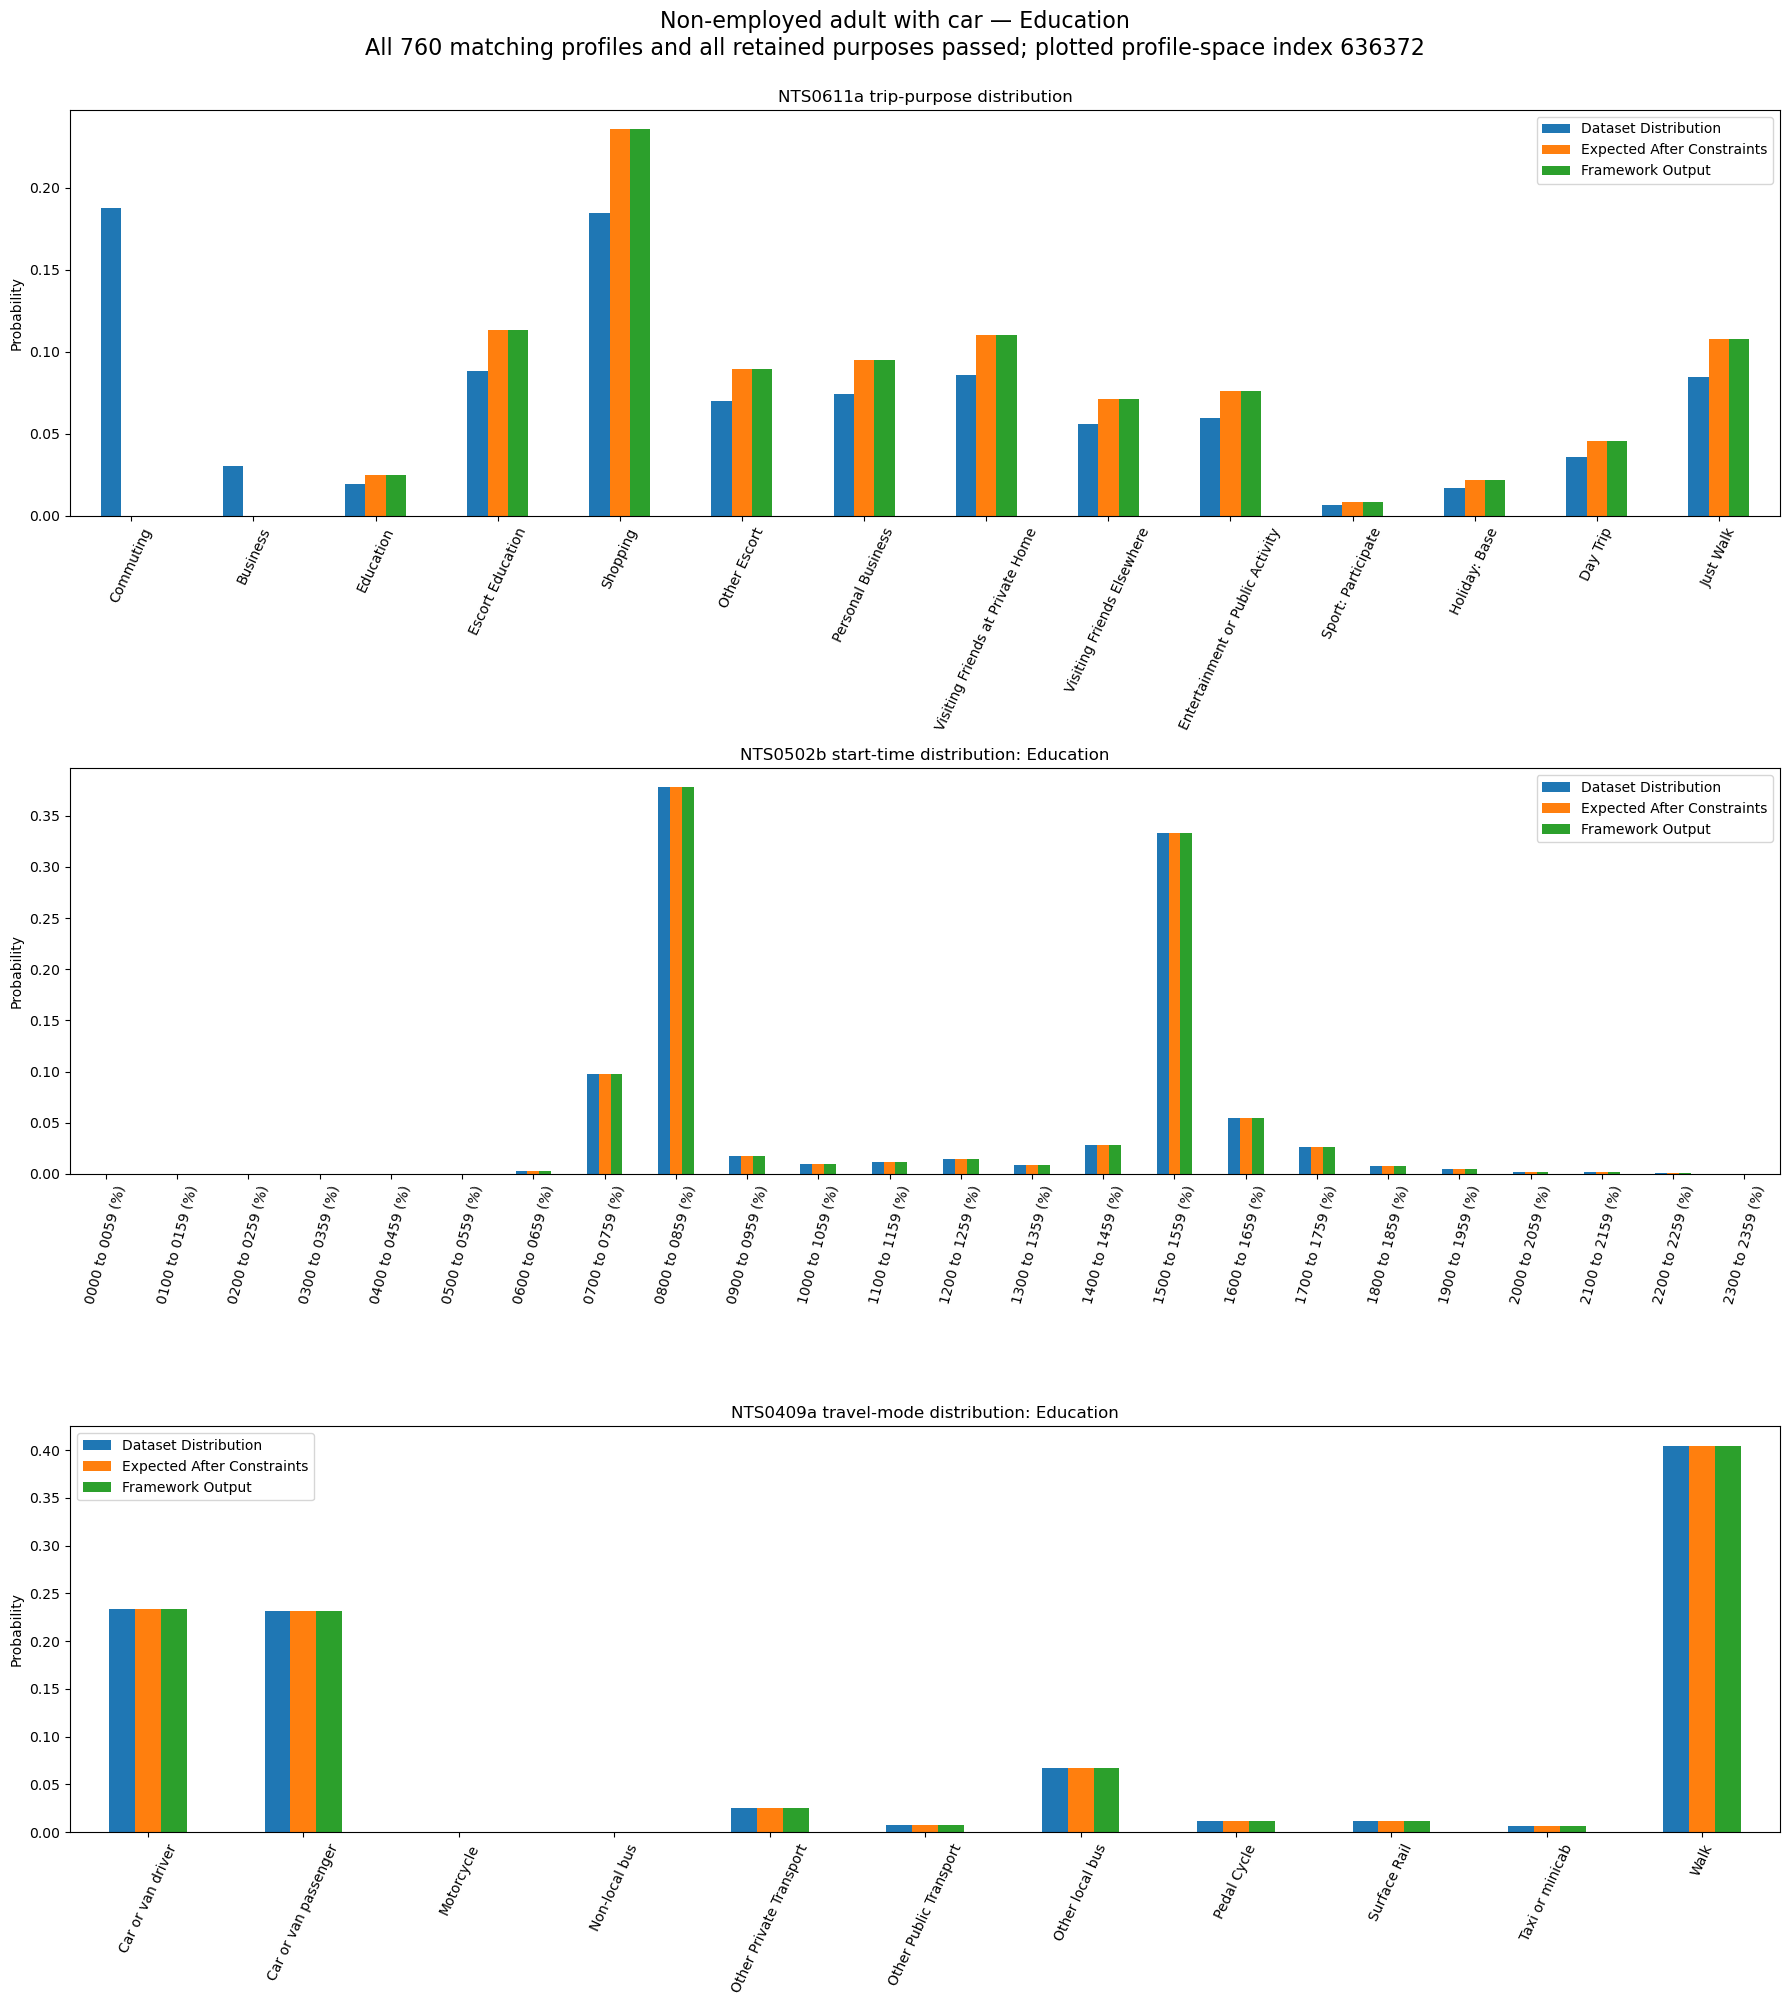

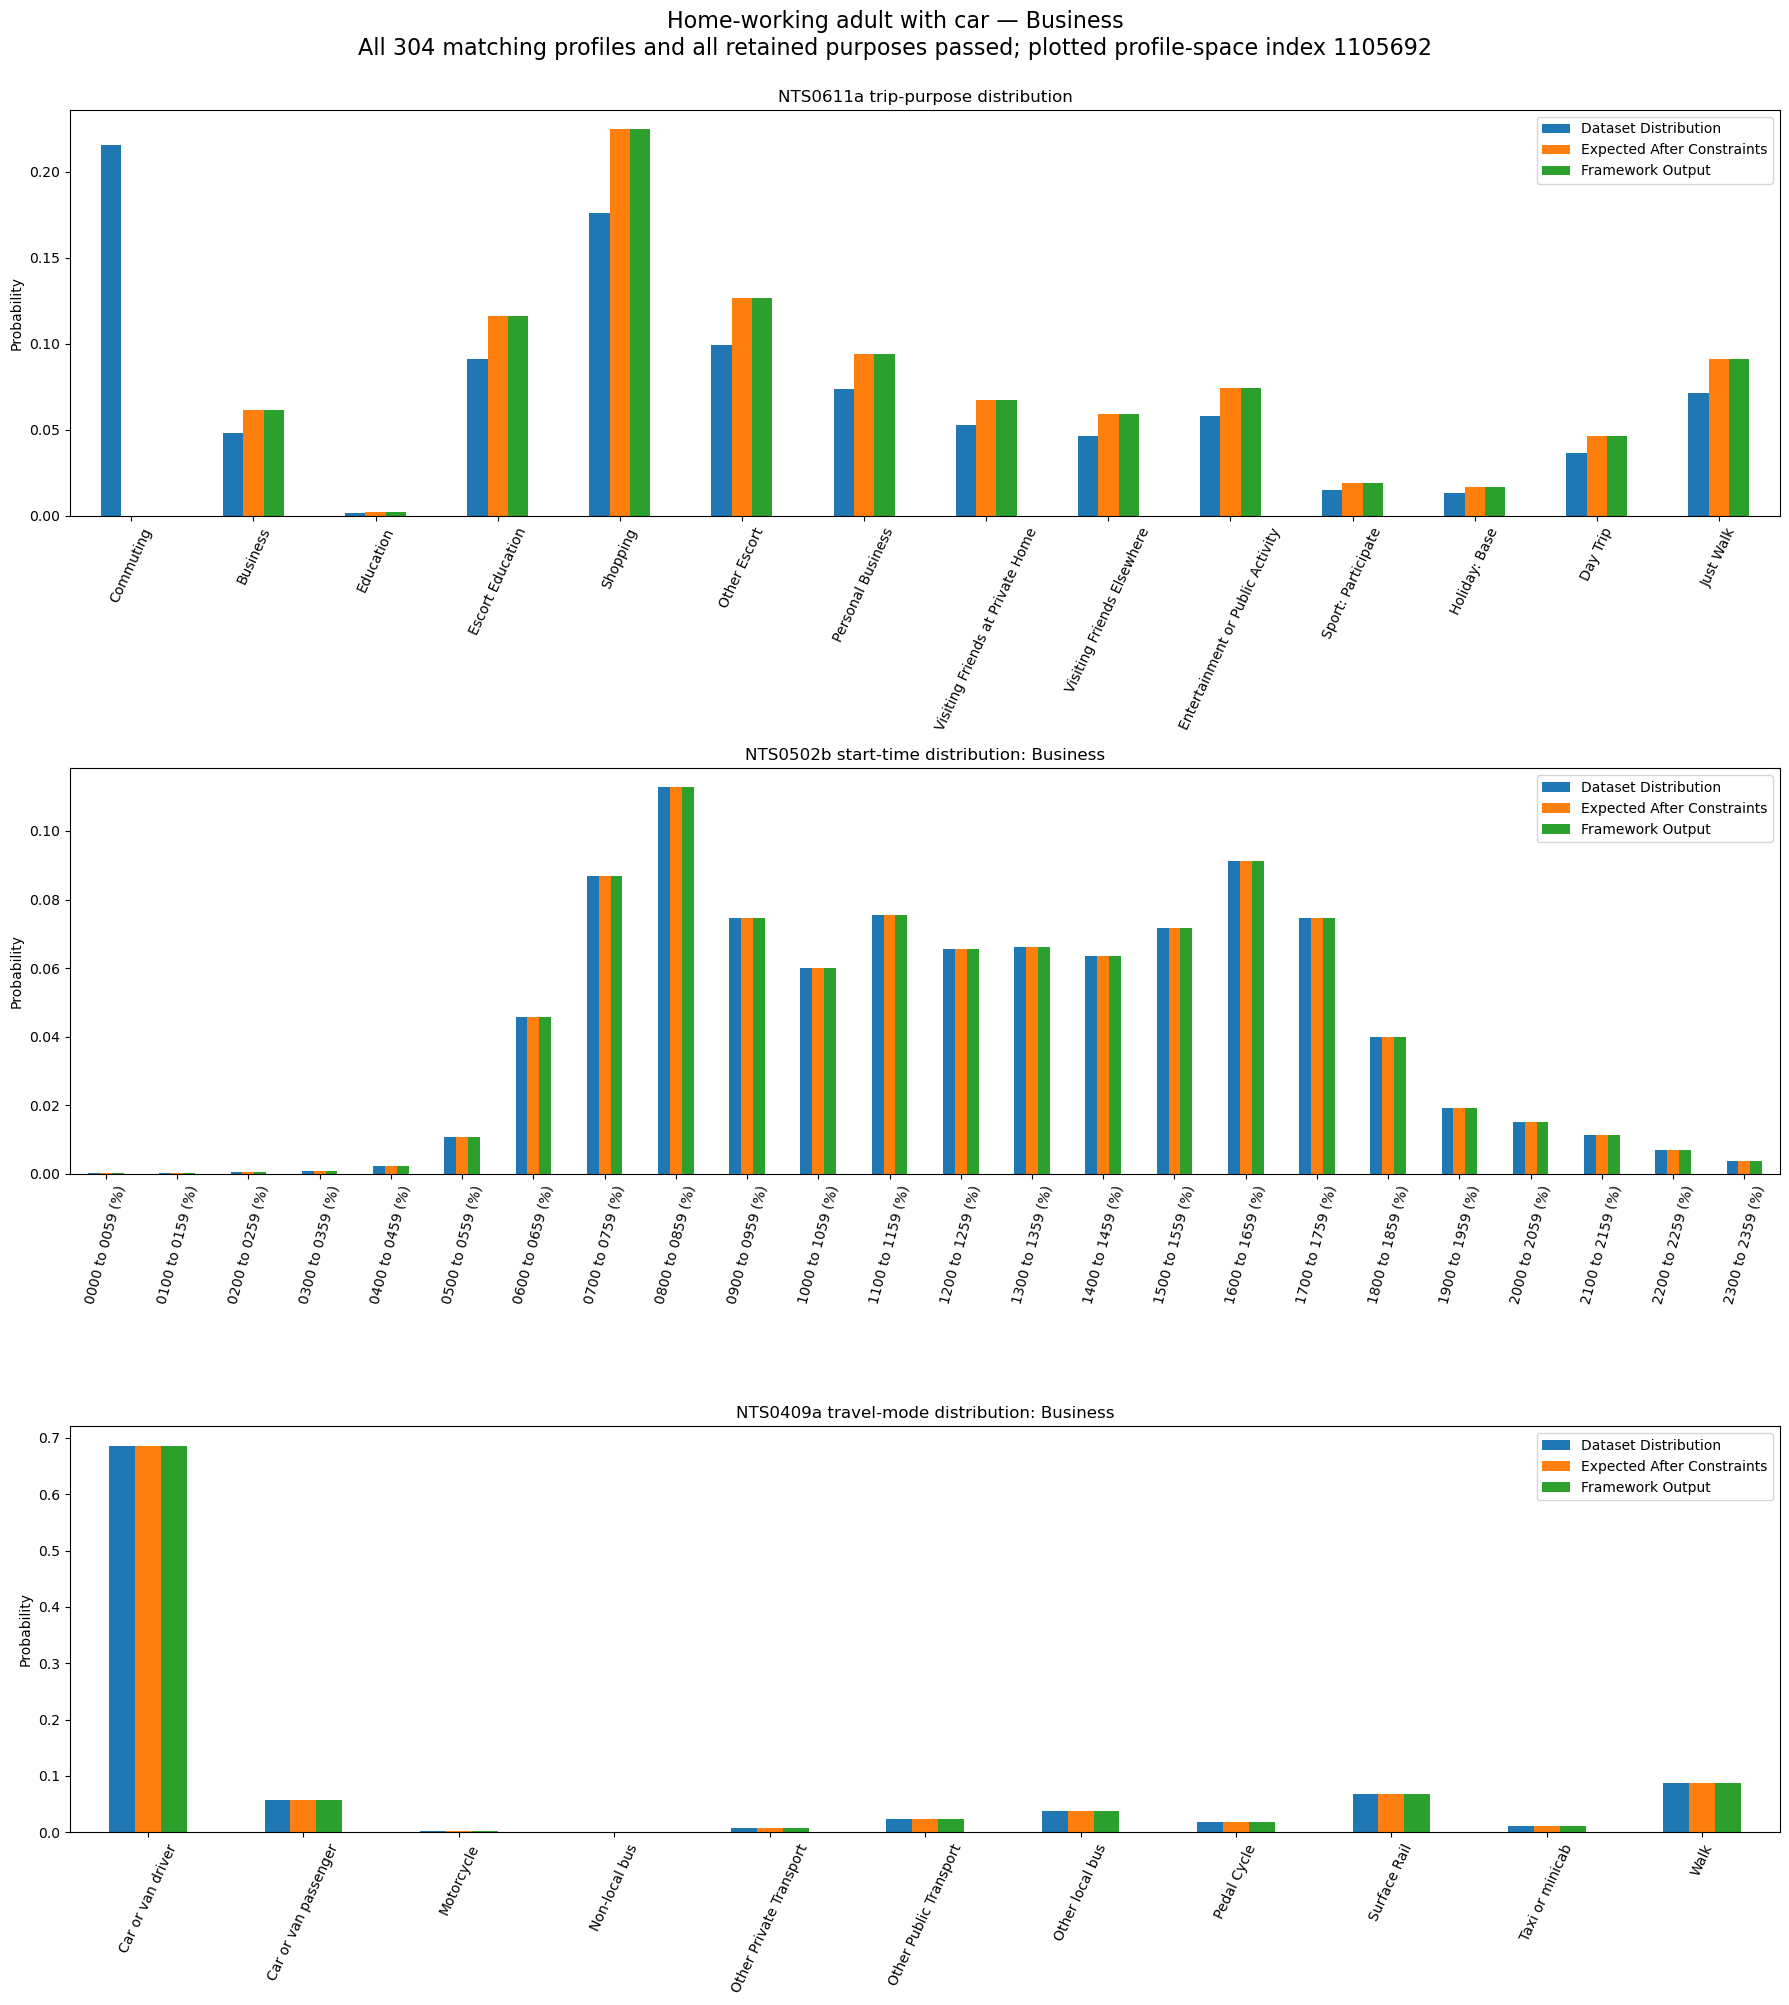

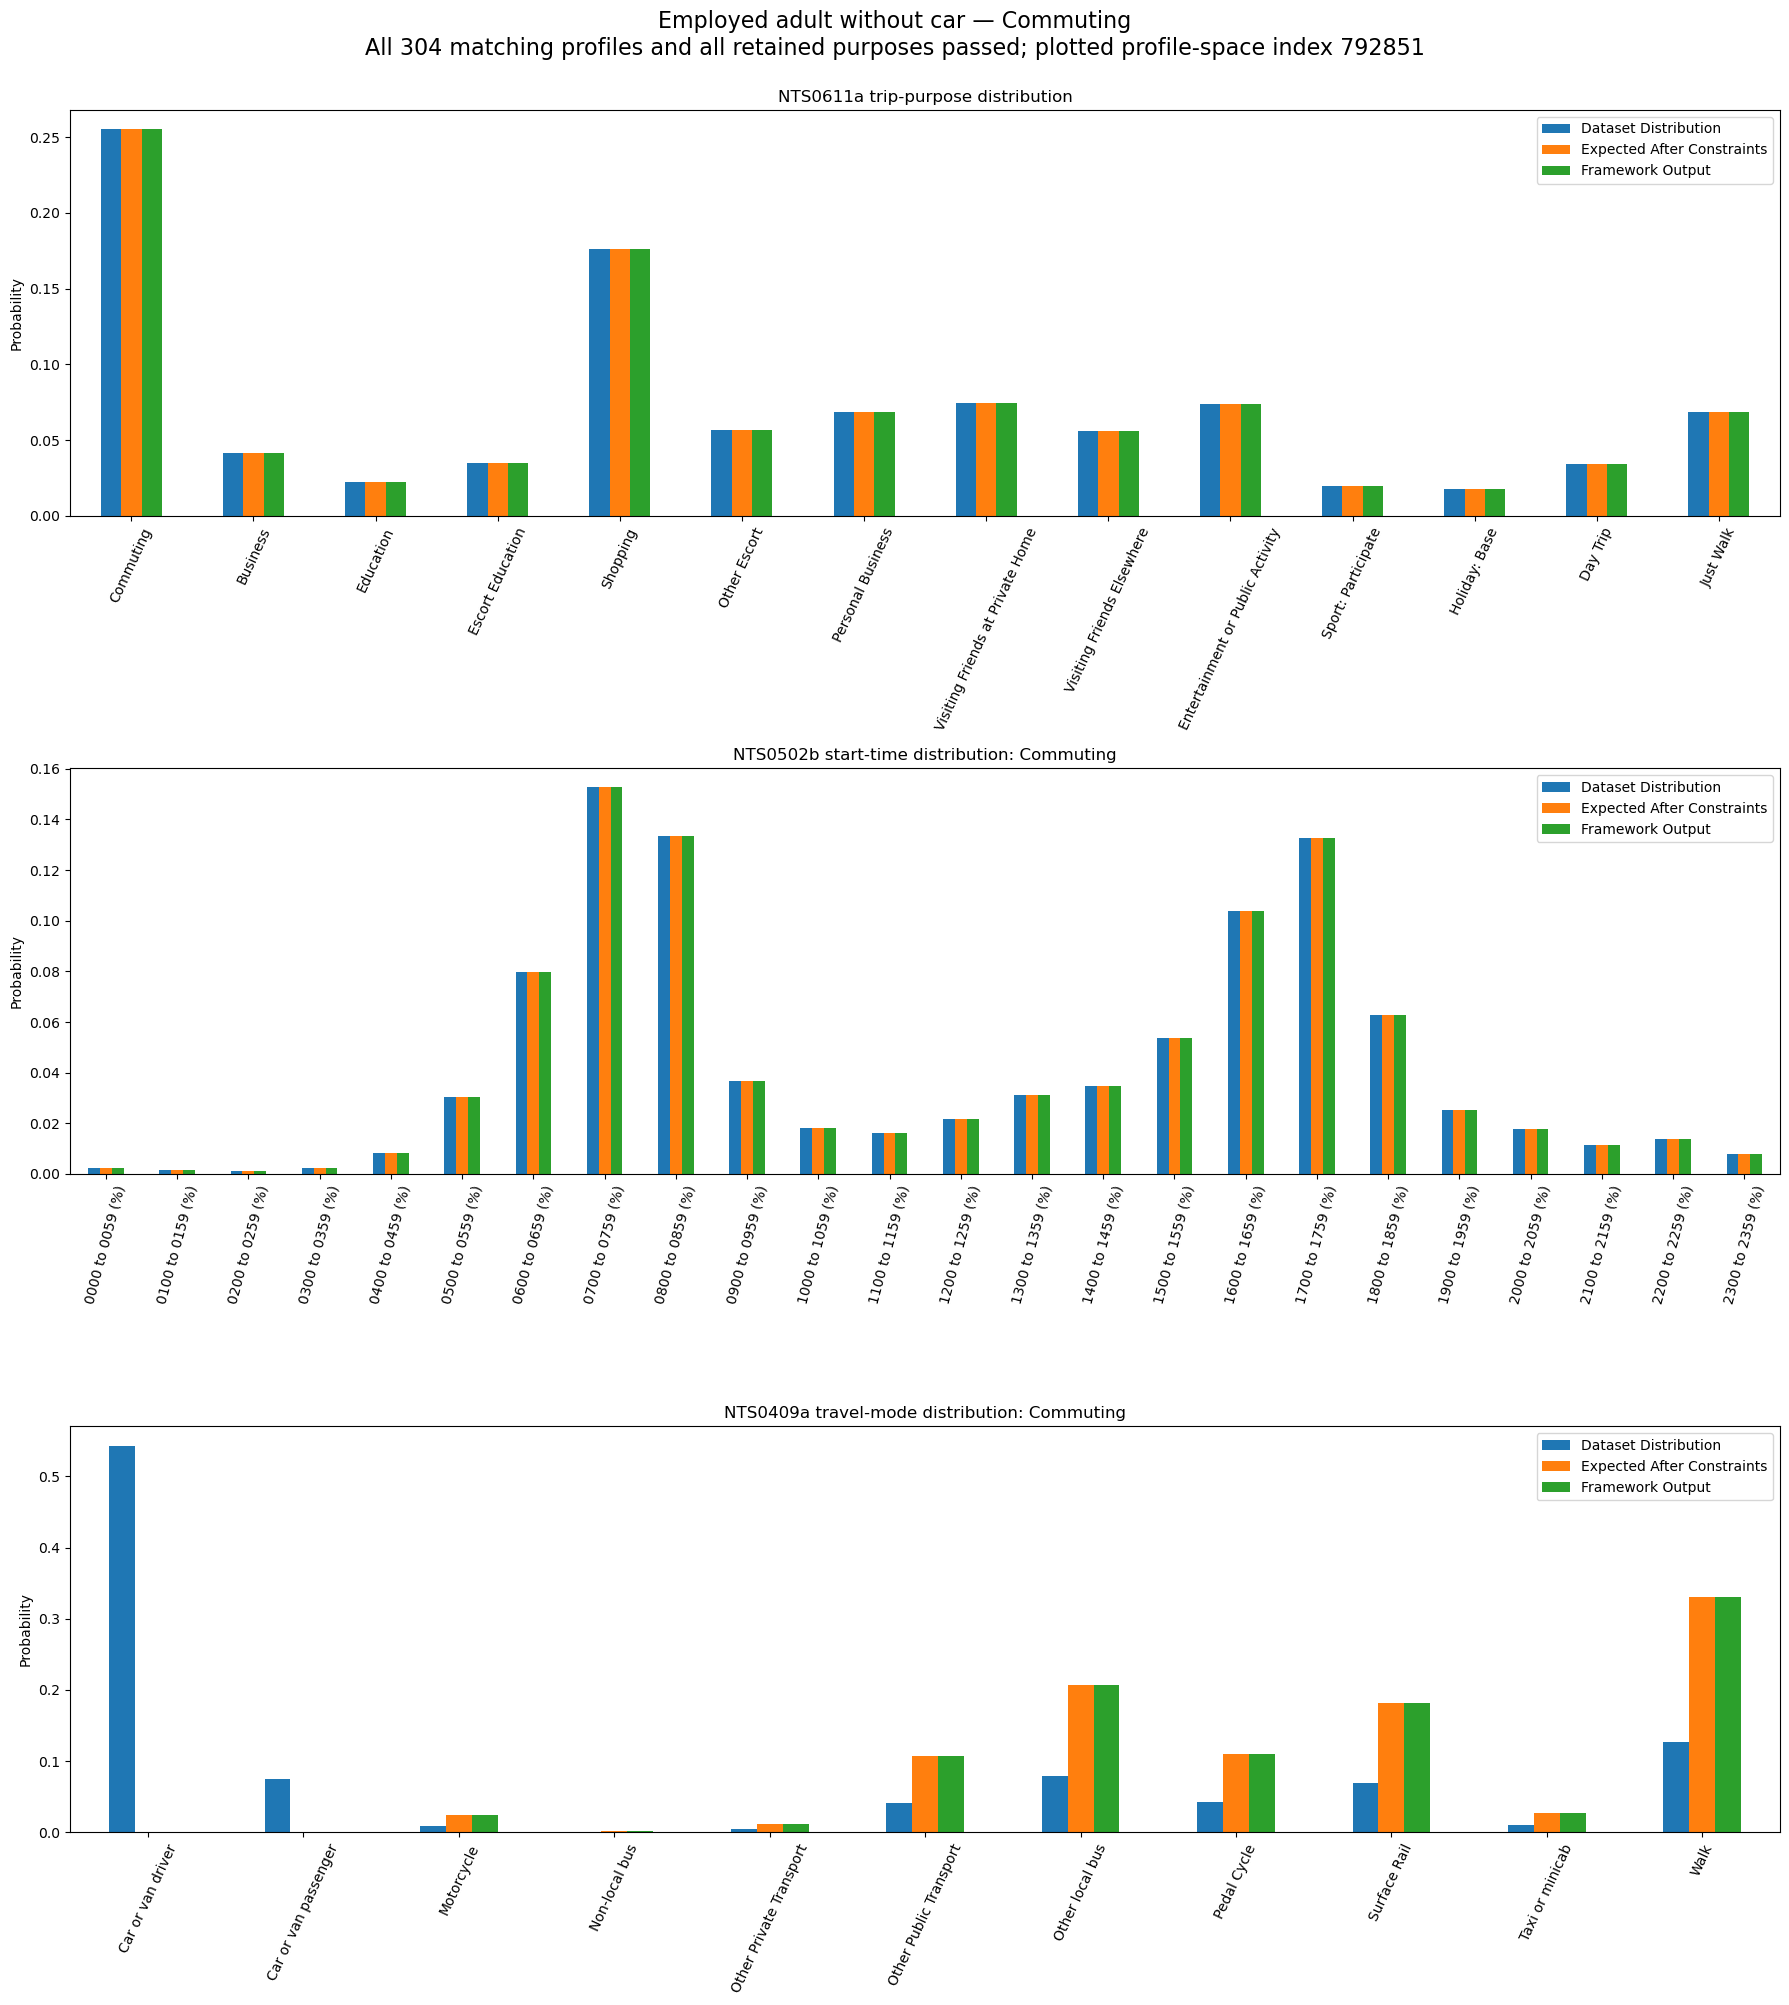

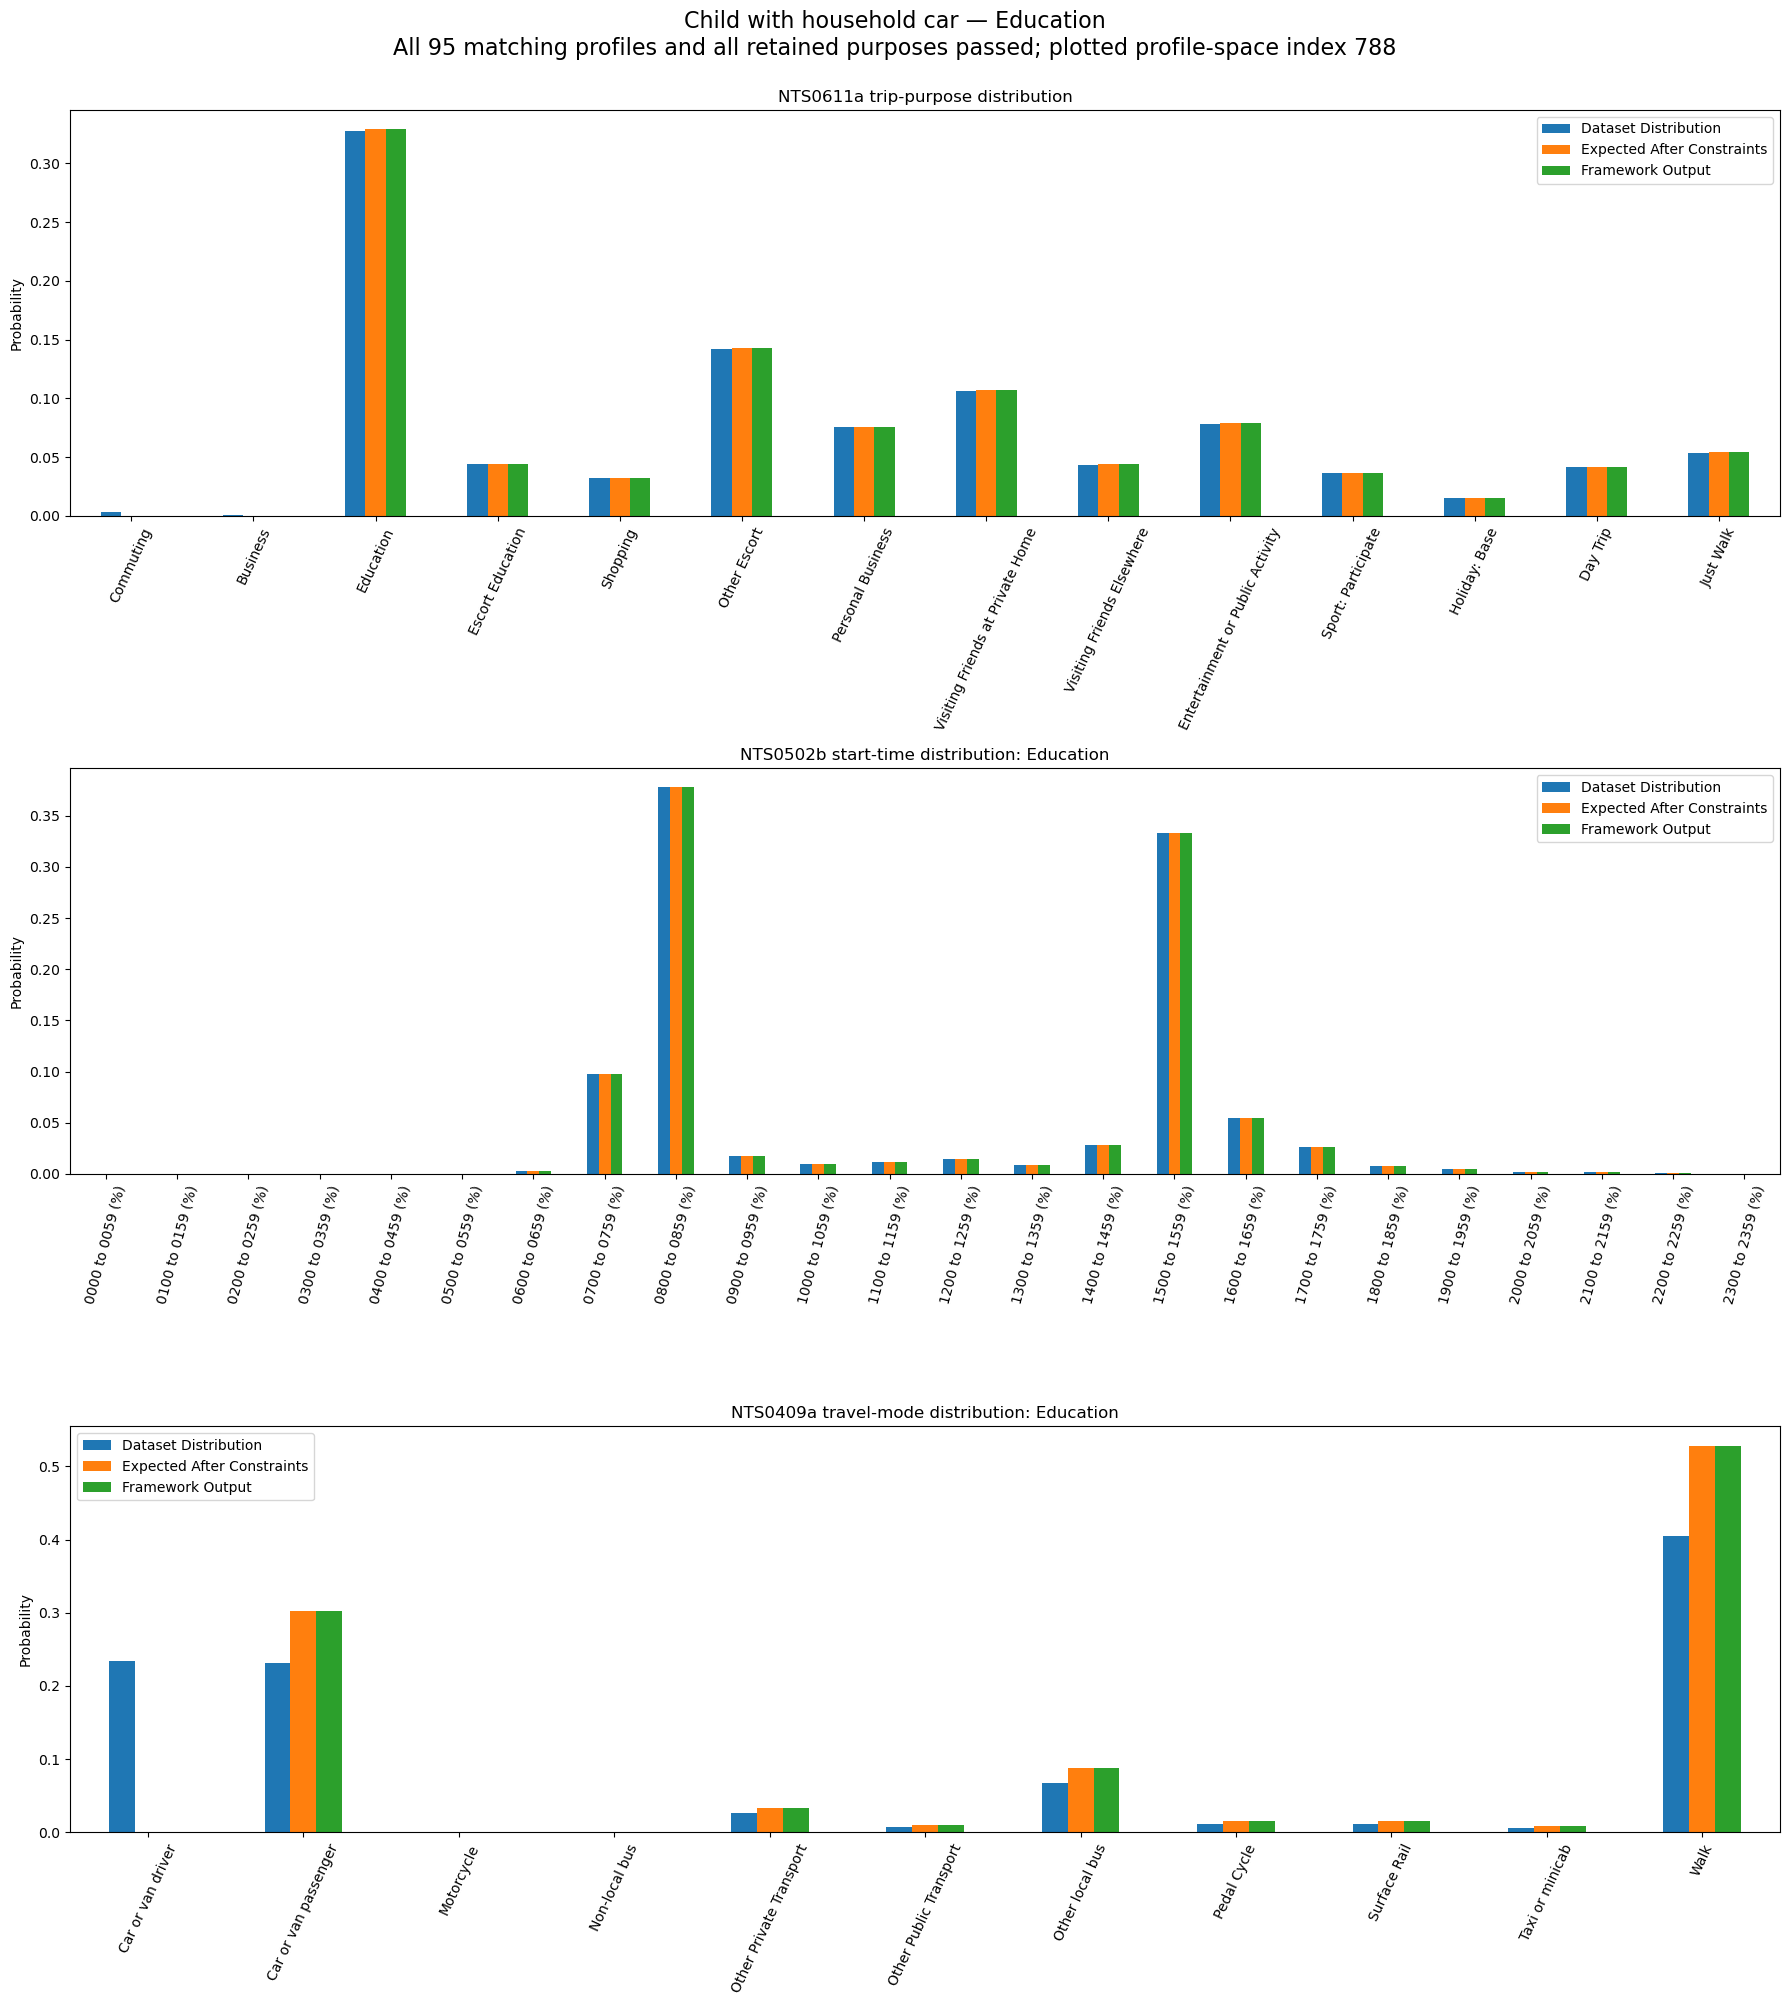

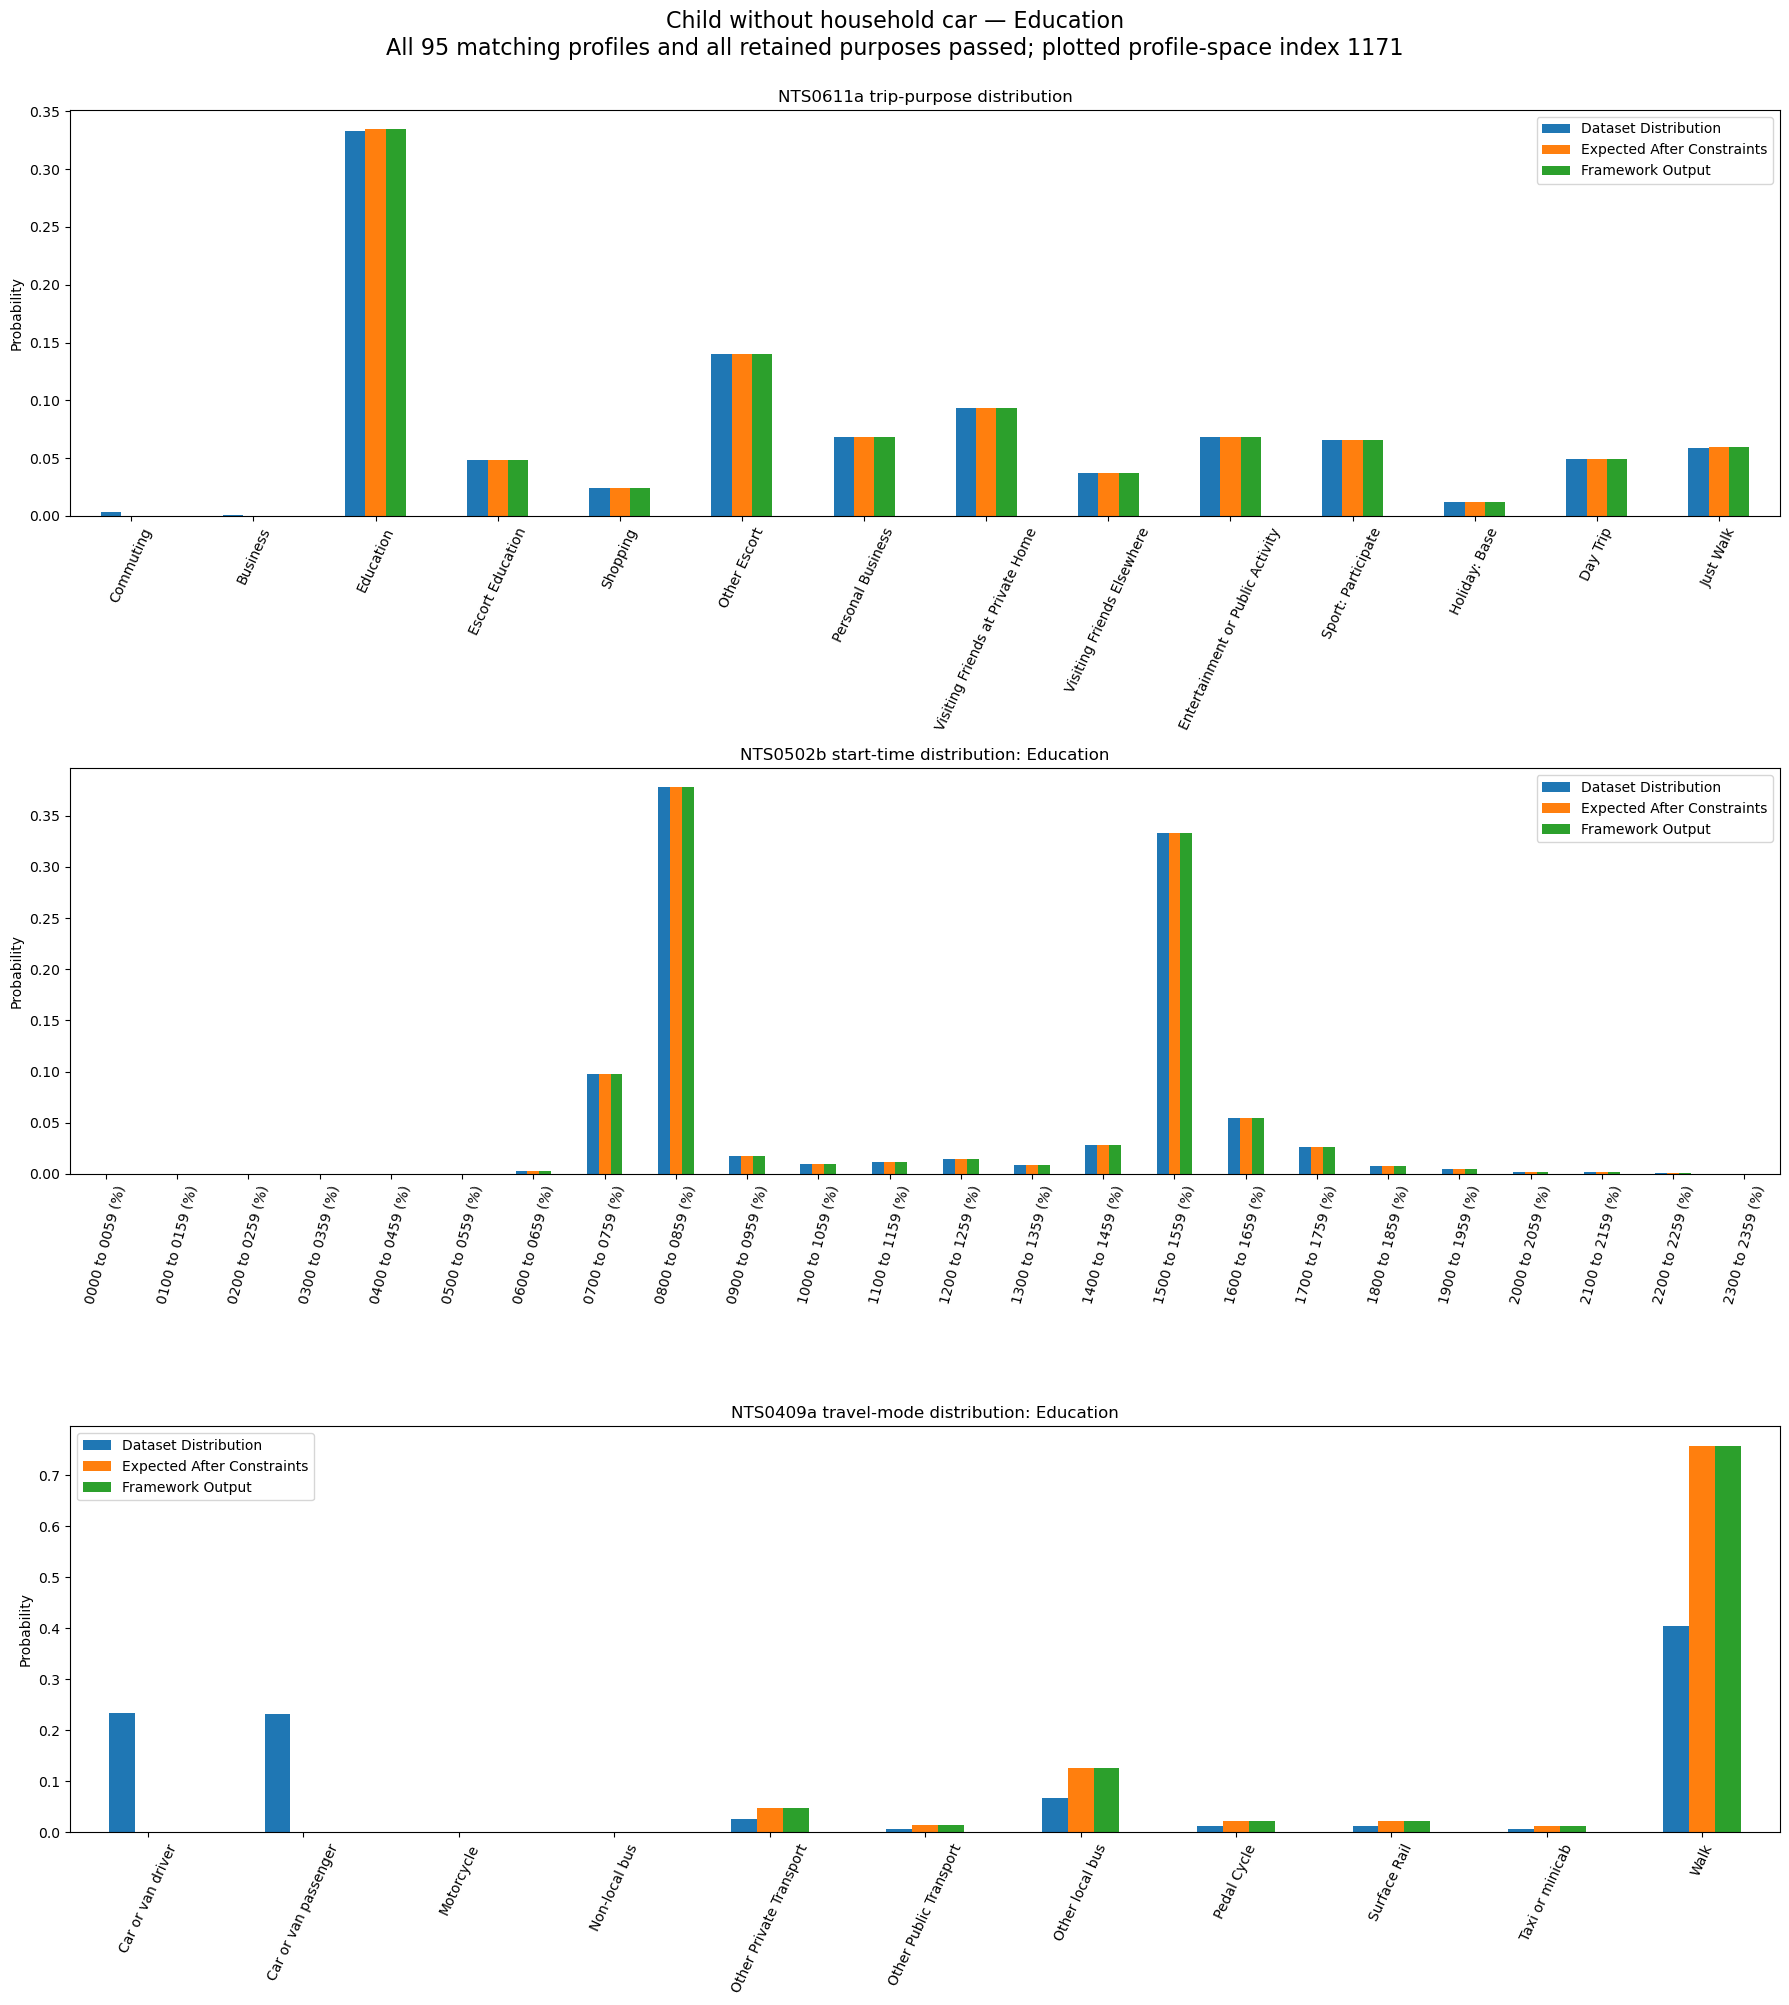

Displayed 5 representative plots and saved all 63 retained-purpose plots to c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework\output\validation\constraint_validation_plots


In [6]:
# AI Collaboration Record
# Tool: ChatGPT
# Purpose: Save a three-component plot for every retained purpose after all
# validations pass, while displaying one plot from each visualisation.
# Prompt:
# See AI_PROMPTS.md


def build_three_distribution_table(
    dataset_distribution,
    expected_after_constraints,
    framework_distribution,
):
    return pd.concat(
        [
            dataset_distribution.rename("Dataset Distribution"),
            expected_after_constraints.reindex(
                dataset_distribution.index,
                fill_value=0.0,
            ).rename("Expected After Constraints"),
            framework_distribution.reindex(
                dataset_distribution.index,
                fill_value=0.0,
            ).rename("Framework Output"),
        ],
        axis=1,
    )


def build_all_purpose_constraint_figure(
    visualisation_name,
    purpose,
    plot_inputs,
    purpose_plot_inputs,
):
    figure, axes = plt.subplots(3, 1, figsize=(18, 20))

    build_three_distribution_table(
        plot_inputs["trip_dataset_distribution"],
        plot_inputs["trip_expected_after_constraints"],
        plot_inputs["framework_trip_distribution"],
    ).plot.bar(ax=axes[0])
    axes[0].set_title("NTS0611a trip-purpose distribution")
    axes[0].set_ylabel("Probability")
    axes[0].tick_params(axis="x", rotation=65)

    build_three_distribution_table(
        purpose_plot_inputs["temporal_dataset_distribution"],
        purpose_plot_inputs[
            "temporal_expected_after_constraints"
        ],
        purpose_plot_inputs["framework_temporal_distribution"],
    ).plot.bar(ax=axes[1])
    axes[1].set_title(
        f"NTS0502b start-time distribution: {purpose}"
    )
    axes[1].set_ylabel("Probability")
    axes[1].tick_params(axis="x", rotation=75)

    build_three_distribution_table(
        purpose_plot_inputs["mode_dataset_distribution"],
        purpose_plot_inputs["mode_expected_after_constraints"],
        purpose_plot_inputs["framework_mode_distribution"],
    ).plot.bar(ax=axes[2])
    axes[2].set_title(
        f"NTS0409a travel-mode distribution: {purpose}"
    )
    axes[2].set_ylabel("Probability")
    axes[2].tick_params(axis="x", rotation=65)

    visualisation_profile_count = expected_profile_counts[
        visualisation_name
    ]
    figure.suptitle(
        f"{visualisation_name} — {purpose}\n"
        f"All {visualisation_profile_count} matching profiles and all "
        "retained purposes passed; plotted profile-space index "
        f"{plot_inputs['profile_space_index']}",
        fontsize=16,
        y=1.0,
    )
    figure.tight_layout()
    return figure


def make_plot_filename(text):
    return "".join(
        character.lower() if character.isalnum() else "_"
        for character in text
    ).strip("_")


assert total_profiles_failed == 0, (
    "Plots are generated only after every matching profile passes."
)
assert len(representative_plot_inputs) == len(
    constraint_visualisations
)

constraint_plot_directory.mkdir(parents=True, exist_ok=True)
all_purpose_plot_paths = {}
displayed_visualisations = set()

for visualisation in constraint_visualisations:
    visualisation_name = visualisation["visualisation"]
    plot_inputs = representative_plot_inputs[visualisation_name]

    for purpose, purpose_plot_inputs in plot_inputs[
        "purpose_validation_results"
    ].items():
        figure = build_all_purpose_constraint_figure(
            visualisation_name,
            purpose,
            plot_inputs,
            purpose_plot_inputs,
        )
        plot_path = constraint_plot_directory / (
            make_plot_filename(visualisation_name)
            + "__"
            + make_plot_filename(purpose)
            + ".png"
        )
        figure.savefig(plot_path, dpi=300, bbox_inches="tight")
        if visualisation_name not in displayed_visualisations:
            plt.show()
            displayed_visualisations.add(visualisation_name)
        plt.close(figure)
        all_purpose_plot_paths[
            (visualisation_name, purpose)
        ] = plot_path

expected_plot_count = sum(
    len(
        plot_inputs["purpose_validation_results"]
    )
    for plot_inputs in representative_plot_inputs.values()
)
assert len(all_purpose_plot_paths) == expected_plot_count
assert len(displayed_visualisations) == len(
    constraint_visualisations
)

print(
    f"Displayed {len(displayed_visualisations)} representative plots "
    f"and saved all {len(all_purpose_plot_paths)} retained-purpose "
    f"plots to {constraint_plot_directory}"
)


### Interpretation

A complete PASS shows that every profile matching each of the five stated constraint visualisations produces the expected transformation across NTS0611 and NTS0409 while preserving the matched NTS0502 temporal distribution for every retained trip purpose. The home-working visualisation also confirms across all matching profiles that Commuting is removed without incorrectly deleting Business. Every retained-purpose figure is produced only after the complete matching-profile and retained-purpose validation has passed.
